# 04 · A/B Test — should Northline ship `checkout_v2`?

**What changed:** `checkout_v2` is a one-page checkout with a free-shipping progress bar ("You're $12 away from free shipping"). To simplify the page, it also removed the "Complete the look" recommendation module.

**Hypothesis:** v2 reduces drop-off at the shipping step, especially on mobile, and raises purchase conversion.

**Design (already run by the product team)**

| Item | Definition |
|---|---|
| Unit of randomization | User (hash of `user_id`, 50/50) |
| Who is in the test | Users who reached `begin_checkout` between Nov 3 and Dec 21, 2025 |
| Exposure | First `begin_checkout` in the window (`exposure_ts`) |
| **Primary metric** | **Conversion:** user placed ≥ 1 order after `exposure_ts`, by Dec 21 23:59 |
| Guardrails | Average order value · revenue per exposed user · payment error rate |
| Decision rule | Two-sided test, α = 0.05; ship only if conversion improves AND no guardrail is significantly worse |

**Notebook plan:** sanity checks → primary metric → segments → effect over time → guardrails → power → decision.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

pd.set_option("display.float_format", "{:,.4f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
CLEAN = Path(r"E:\Northline\clean")
rng = np.random.default_rng(7)

TEST_END = pd.Timestamp("2025-12-21 23:59:59")
COLORS = {"control": "#8C8C8C", "treatment": "#DD8452"}

a = pd.read_parquet(CLEAN / "experiment_assignments.parquet")
orders = pd.read_parquet(CLEAN / "orders.parquet")
users = pd.read_parquet(CLEAN / "users.parquet", columns=["user_id", "loyalty_member"])
a = a.merge(users, on="user_id", how="left")
print(f"Exposed users: {len(a):,}")
a.head()

Exposed users: 12,249


,user_id,experiment_id,variant,exposure_ts,exposure_device,exposure_browser,loyalty_member
0,U76638182,checkout_v2,treatment,2025-12-18 08:34:47,mobile,Chrome,False
1,U36809211,checkout_v2,control,2025-11-23 14:45:15,desktop,Chrome,False
2,U71608029,checkout_v2,treatment,2025-11-28 16:50:06,mobile,Chrome,False
3,U31021023,checkout_v2,control,2025-12-12 19:06:56,desktop,Edge,False
4,U67365653,checkout_v2,control,2025-12-19 10:26:00,desktop,Edge,False


## Sanity checks (before looking at any result)

### Sample ratio mismatch (SRM)
With a 50/50 split, the two groups should be about equal in size. A significant imbalance means the randomization or the logging is broken, and **no result can be trusted**. The usual alarm level is p < 0.01.

In [2]:
counts = a.variant.value_counts()
chi2, p_srm = stats.chisquare(counts.values)
print(counts.to_string())
print(f"\nShare in treatment: {counts['treatment'] / counts.sum():.2%}")
print(f"SRM chi-square p-value: {p_srm:.3f} -> {'PASS' if p_srm >= 0.01 else 'FAIL: stop and investigate'}")

variant
control      6154
treatment    6095

Share in treatment: 49.76%
SRM chi-square p-value: 0.594 -> PASS


### Balance — are the groups alike before treatment?

In [3]:
bal = pd.concat({
    "device": pd.crosstab(a.exposure_device, a.variant, normalize="columns"),
    "browser": pd.crosstab(a.exposure_browser, a.variant, normalize="columns"),
    "loyalty member": pd.crosstab(a.loyalty_member, a.variant, normalize="columns"),
})
bal["difference (pts)"] = (bal.treatment - bal.control) * 100
bal.style.format({"control": "{:.1%}", "treatment": "{:.1%}", "difference (pts)": "{:+.1f}"})

Mix differences are within about a point: randomization worked. Results can be compared directly.

## Build the outcome table — one row per exposed user

In [4]:
o = orders.merge(a[["user_id", "variant", "exposure_ts"]], on="user_id")
o = o[(o.order_ts >= o.exposure_ts) & (o.order_ts <= TEST_END)].sort_values("order_ts")

per_user = o.groupby("user_id").agg(orders=("order_id", "size"),
                                     revenue=("order_revenue", "sum"),
                                     first_order_value=("order_revenue", "first"),
                                     first_order_items=("n_line_items", "first"),
                                     first_order_subtotal=("subtotal", "first"))
u = a.merge(per_user, on="user_id", how="left")
u["converted"] = u.orders.notna()
u[["orders", "revenue"]] = u[["orders", "revenue"]].fillna(0)
u.groupby("variant", observed=True)[["converted", "orders", "revenue"]].mean()

,converted,orders,revenue
variant,,,
control,0.7028,0.7322,93.5849
treatment,0.7408,0.7752,94.2593


## Primary metric — conversion

In [5]:
def compare_props(df, label="All exposed users"):
    g = df.groupby("variant", observed=True).converted.agg(["sum", "count"])
    x_t, n_t = g.loc["treatment"]; x_c, n_c = g.loc["control"]
    p_t, p_c = x_t / n_t, x_c / n_c
    z, p = proportions_ztest([x_t, x_c], [n_t, n_c])
    lo, hi = confint_proportions_2indep(x_t, n_t, x_c, n_c, method="wald")
    return pd.Series({"segment": label, "n_control": n_c, "n_treatment": n_t,
                      "control": p_c, "treatment": p_t,
                      "lift_pts": (p_t - p_c) * 100, "ci_low_pts": lo * 100, "ci_high_pts": hi * 100,
                      "relative_lift": (p_t / p_c - 1), "p_value": p})

primary = compare_props(u)
primary.to_frame("value")

,value
segment,All exposed users
n_control,6154
n_treatment,6095
control,0.7028
treatment,0.7408
lift_pts,3.7976
ci_low_pts,2.2120
ci_high_pts,5.3832
relative_lift,0.0540
p_value,0.0000


In [6]:
print(f"Conversion: control {primary.control:.1%} -> treatment {primary.treatment:.1%}")
print(f"Lift: {primary.lift_pts:+.1f} pts ({primary.relative_lift:+.1%} relative), "
      f"95% CI [{primary.ci_low_pts:+.1f}, {primary.ci_high_pts:+.1f}] pts, p = {primary.p_value:.2g}")

Conversion: control 70.3% -> treatment 74.1%
Lift: +3.8 pts (+5.4% relative), 95% CI [+2.2, +5.4] pts, p = 2.7e-06


**Result:** v2 raises conversion by about 4 points, and the 95% confidence interval is well above zero. The effect is real, not noise.


## Where does the lift come from?

In [7]:
seg = [primary]
for dev in ["mobile", "desktop", "tablet"]:
    seg.append(compare_props(u[u.exposure_device == dev], f"device: {dev}"))
for mem, lab in [(True, "loyalty member"), (False, "non-member")]:
    seg.append(compare_props(u[u.loyalty_member == mem], lab))
segments = pd.DataFrame(seg).set_index("segment")
(segments.style.format({"n_control": "{:,.0f}", "n_treatment": "{:,.0f}", "control": "{:.1%}",
                        "treatment": "{:.1%}", "lift_pts": "{:+.1f}", "ci_low_pts": "{:+.1f}",
                        "ci_high_pts": "{:+.1f}", "relative_lift": "{:+.1%}", "p_value": "{:.3f}"}))

,n_control,n_treatment,control,treatment,lift_pts,ci_low_pts,ci_high_pts,relative_lift,p_value
segment,,,,,,,,,
All exposed users,"6,154","6,095",70.3%,74.1%,+3.8,+2.2,+5.4,+5.4%,0.000
device: mobile,"3,531","3,457",66.9%,72.2%,+5.3,+3.1,+7.4,+7.9%,0.000
device: desktop,"2,196","2,162",75.2%,77.7%,+2.4,-0.1,+5.0,+3.2%,0.059
device: tablet,427,476,72.8%,71.6%,-1.2,-7.0,+4.7,-1.6%,0.689
loyalty member,"1,867","1,914",73.2%,76.2%,+3.1,+0.3,+5.8,+4.2%,0.030
non-member,"4,287","4,181",69.0%,73.1%,+4.1,+2.1,+6.0,+5.9%,0.000


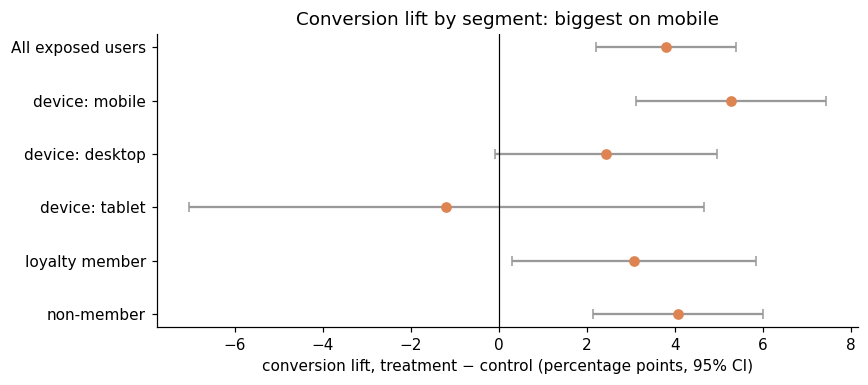

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
sd = segments.iloc[::-1]
ypos = np.arange(len(sd))
ax.errorbar(sd.lift_pts, ypos, xerr=[sd.lift_pts - sd.ci_low_pts, sd.ci_high_pts - sd.lift_pts],
            fmt="o", color="#DD8452", ecolor="#999", capsize=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(ypos, sd.index)
ax.set_xlabel("conversion lift, treatment − control (percentage points, 95% CI)")
ax.set_title("Conversion lift by segment: biggest on mobile")
plt.tight_layout(); plt.show()

**Mobile carries most of the win** (about +5 pts), and non-members gain more than loyalty members. That matches the funnel diagnosis: the leak was fee shock at the shipping step for non-members on mobile, and the progress bar targets exactly that. The desktop and tablet CIs include zero, so there's no clear evidence v2 helps there.

Segment results are **exploratory**: with 6 cuts, one could look significant by chance. Here the pattern matches a mechanism we identified *before* the test, which makes it credible.

## Effect over time — is there a novelty effect?

New designs often get a short-lived boost because they're new. Two views: users grouped by the week they were first exposed, and the mobile shipping step (where v2 acts) by calendar week.

In [9]:
u["exposure_week"] = ((u.exposure_ts - pd.Timestamp("2025-11-03")).dt.days // 7 + 1).clip(upper=7)
weekly = pd.DataFrame([compare_props(u[u.exposure_week == w], f"week {w}") for w in range(1, 8)]).set_index("segment")
weekly[["n_control", "n_treatment", "control", "treatment", "lift_pts", "ci_low_pts", "ci_high_pts"]]

,n_control,n_treatment,control,treatment,lift_pts,ci_low_pts,ci_high_pts
segment,,,,,,,
week 1,421,439,0.7387,0.7790,4.0326,-1.6836,9.7487
week 2,491,460,0.7251,0.7043,-2.0703,-7.8137,3.6731
week 3,581,592,0.6936,0.7534,5.9747,0.8652,11.0842
week 4,1303,1287,0.7099,0.7692,5.9331,2.5611,9.3050
week 5,1320,1288,0.7038,0.7422,3.8448,0.4136,7.2760
week 6,1035,1029,0.6976,0.7483,5.0715,1.2164,8.9265
week 7,1003,1000,0.6770,0.6870,1.0031,-3.0756,5.0818


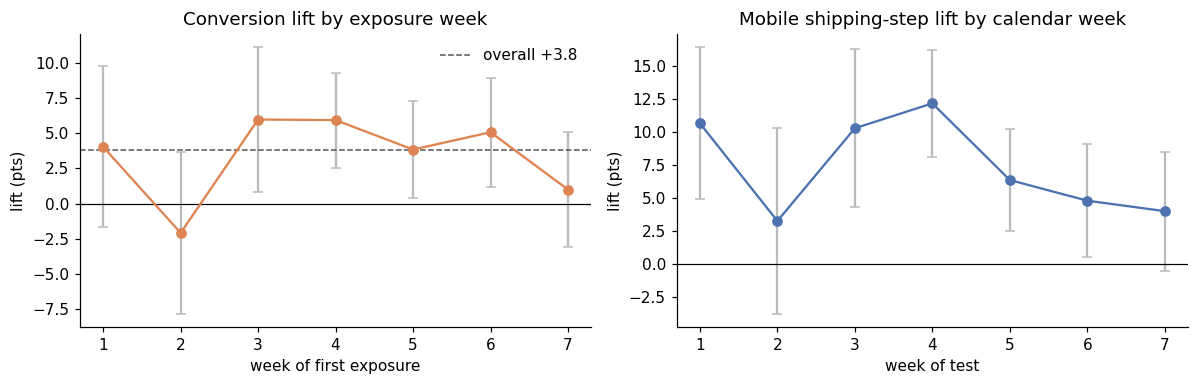

,week,1,2,3,4,5,6,7
,variant,,,,,,,
lift_pts,,10.7000,3.3000,10.3000,12.2000,6.4000,4.8000,4.0000


In [10]:
ev = pd.read_parquet(CLEAN / "events.parquet", columns=["session_id", "user_id", "event_name", "event_ts"],
                     filters=[("event_name", "in", ["begin_checkout", "add_shipping_info"])])
ev = ev[ev.user_id.isin(a.user_id)]
fs = ev.groupby(["session_id", "event_name"], observed=True).event_ts.min().unstack()
fs = fs[fs.begin_checkout.between(pd.Timestamp("2025-11-03"), TEST_END)]
fs["passed"] = fs.add_shipping_info.notna()
sess = pd.read_parquet(CLEAN / "sessions.parquet", columns=["session_id", "user_id", "device"]).set_index("session_id")
fs = fs.join(sess).merge(a[["user_id", "variant"]], on="user_id")
fs["week"] = ((fs.begin_checkout - pd.Timestamp("2025-11-03")).dt.days // 7 + 1).clip(upper=7)

mw = fs[fs.device == "mobile"].groupby(["week", "variant"], observed=True).passed.agg(["mean", "size"]).unstack()
mw["lift_pts"] = (mw[("mean", "treatment")] - mw[("mean", "control")]) * 100
se = np.sqrt(mw[("mean", "treatment")] * (1 - mw[("mean", "treatment")]) / mw[("size", "treatment")]
             + mw[("mean", "control")] * (1 - mw[("mean", "control")]) / mw[("size", "control")]) * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].errorbar(weekly.index.str.replace("week ", ""), weekly.lift_pts,
                 yerr=[weekly.lift_pts - weekly.ci_low_pts, weekly.ci_high_pts - weekly.lift_pts],
                 fmt="o-", color="#DD8452", ecolor="#bbb", capsize=3)
axes[0].axhline(primary.lift_pts, ls="--", color="#555", lw=1, label=f"overall {primary.lift_pts:+.1f}")
axes[0].set(title="Conversion lift by exposure week", xlabel="week of first exposure", ylabel="lift (pts)")
axes[0].legend(frameon=False)
axes[1].errorbar(mw.index.astype(str), mw.lift_pts, yerr=1.96 * se, fmt="o-", color="#4C72B0", ecolor="#bbb", capsize=3)
axes[1].set(title="Mobile shipping-step lift by calendar week", xlabel="week of test", ylabel="lift (pts)")
for ax in axes: ax.axhline(0, color="black", lw=0.8)
plt.tight_layout(); plt.show()
mw[["lift_pts"]].T.round(1)

In [11]:
early = fs[(fs.device == "mobile") & (fs.week == 1)]
later = fs[(fs.device == "mobile") & (fs.week >= 3)]
for name, d in [("week 1", early), ("weeks 3-7", later)]:
    r = d.groupby("variant", observed=True).passed.mean()
    print(f"Mobile shipping-step pass rate, {name}: control {r.control:.1%}, treatment {r.treatment:.1%}, "
          f"lift {(r.treatment - r.control) * 100:+.1f} pts")

Mobile shipping-step pass rate, week 1: control 81.7%, treatment 92.3%, lift +10.7 pts
Mobile shipping-step pass rate, weeks 3-7: control 75.0%, treatment 82.4%, lift +7.4 pts


**Reading:** the mobile shipping-step lift in week 1 is above the weeks 3–7 average, which is what a novelty effect would look like. But weekly estimates bounce around (each week has only a few hundred users per arm, and weeks 3–4 are just as high), so the evidence for novelty is **weak**. The safe choice is to plan with the later-weeks number and confirm in a longer, non-holiday test.

## Guardrails

### Average order value (first order after exposure)
Order values are right-skewed, so alongside Welch's t-test we use a **Mann-Whitney** test and a **bootstrap** CI for the difference in means.

In [12]:
def bootstrap_diff(x, y, n=5000, stat=np.mean):
    x, y = np.asarray(x), np.asarray(y)
    diffs = np.array([stat(rng.choice(x, len(x))) - stat(rng.choice(y, len(y))) for _ in range(n)])
    return np.percentile(diffs, [2.5, 97.5])

buyers = u[u.converted]
aov_t = buyers.loc[buyers.variant == "treatment", "first_order_value"]
aov_c = buyers.loc[buyers.variant == "control", "first_order_value"]
lo, hi = bootstrap_diff(aov_t, aov_c)
aov = pd.Series({
    "control AOV": aov_c.mean(), "treatment AOV": aov_t.mean(),
    "difference $": aov_t.mean() - aov_c.mean(), "difference %": aov_t.mean() / aov_c.mean() - 1,
    "bootstrap 95% CI low $": lo, "bootstrap 95% CI high $": hi,
    "Welch t-test p": stats.ttest_ind(aov_t, aov_c, equal_var=False).pvalue,
    "Mann-Whitney p": stats.mannwhitneyu(aov_t, aov_c).pvalue,
    "control median": aov_c.median(), "treatment median": aov_t.median(),
})
aov.to_frame("value")

,value
control AOV,128.4029
treatment AOV,121.6200
difference $,-6.7828
difference %,-0.0528
bootstrap 95% CI low $,-11.2944
bootstrap 95% CI high $,-2.1394
Welch t-test p,0.0042
Mann-Whitney p,0.0000
control median,92.6400
treatment median,85.8200


**AOV is significantly lower in treatment.** Why? Two candidate causes:
1. **Mix shift:** v2 rescues *extra* small-cart shoppers who would otherwise have left, so more small orders enter the average. That isn't a loss.
2. **The removed upsell:** "Complete the look" added items to some control orders. That *is* a loss.

In [13]:
buyers = buyers.assign(small=buyers.first_order_subtotal < 49)
mix = buyers.groupby("variant", observed=True).agg(
    buyers=("user_id", "size"),
    share_small_orders=("small", "mean"),
    items_per_order=("first_order_items", "mean"),
)
mix["AOV, orders $49+ only"] = buyers[~buyers.small].groupby("variant", observed=True).first_order_value.mean()
mix["AOV, orders under $49 only"] = buyers[buyers.small].groupby("variant", observed=True).first_order_value.mean()
mix

,buyers,share_small_orders,items_per_order,"AOV, orders $49+ only","AOV, orders under $49 only"
variant,,,,,
control,4325,0.1820,1.9695,149.0206,35.7147
treatment,4515,0.2140,1.8303,145.0993,35.3593


In [14]:
big_t = buyers[(buyers.variant == "treatment") & ~buyers.small].first_order_value
big_c = buyers[(buyers.variant == "control") & ~buyers.small].first_order_value
items_t = buyers[buyers.variant == "treatment"].first_order_items
items_c = buyers[buyers.variant == "control"].first_order_items
print(f"Within $49+ orders, AOV difference: {big_t.mean() - big_c.mean():+.2f} "
      f"(Mann-Whitney p = {stats.mannwhitneyu(big_t, big_c).pvalue:.3f})")
print(f"Items per order difference: {items_t.mean() - items_c.mean():+.3f} "
      f"(Mann-Whitney p = {stats.mannwhitneyu(items_t, items_c).pvalue:.3g})")

Within $49+ orders, AOV difference: -3.92 (Mann-Whitney p = 0.049)
Items per order difference: -0.139 (Mann-Whitney p = 8.89e-09)


**Both causes are at work:** treatment has a larger share of small orders (mix shift), *and* fewer items per order even among bigger baskets, consistent with losing the "Complete the look" upsell. The mix-shift part is harmless; the upsell part is a fixable loss.

### Revenue per exposed user — the metric that combines conversion and AOV

In [15]:
r_t = u.loc[u.variant == "treatment", "revenue"]; r_c = u.loc[u.variant == "control", "revenue"]
lo, hi = bootstrap_diff(r_t, r_c)
rpu = pd.Series({"control $/user": r_c.mean(), "treatment $/user": r_t.mean(),
                 "difference $": r_t.mean() - r_c.mean(), "difference %": r_t.mean() / r_c.mean() - 1,
                 "bootstrap 95% CI low $": lo, "bootstrap 95% CI high $": hi,
                 "Welch t-test p": stats.ttest_ind(r_t, r_c, equal_var=False).pvalue})
rpu.to_frame("value")

,value
control $/user,93.5849
treatment $/user,94.2593
difference $,0.6744
difference %,0.0072
bootstrap 95% CI low $,-3.3555
bootstrap 95% CI high $,4.7190
Welch t-test p,0.7433


**Revenue per user is flat:** more buyers, but smaller orders, roughly cancel out. The CI includes zero and allows anything from a small loss to a small gain.

### Payment errors

In [17]:
pe = pd.read_parquet(CLEAN / "events.parquet", columns=["session_id", "user_id", "event_name", "event_ts", "payment_type"],
                     filters=[("event_name", "in", ["add_payment_info", "payment_error"])])
pe = pe[pe.user_id.isin(a.user_id) & pe.event_ts.between(pd.Timestamp("2025-11-03"), TEST_END)]
pe = pe.merge(a[["user_id", "variant", "exposure_ts"]], on="user_id")
pe = pe[pe.event_ts >= pe.exposure_ts]

att = pe[pe.event_name == "add_payment_info"].groupby(["payment_type", "variant"], observed=True).session_id.nunique()
err = pe[pe.event_name == "payment_error"].groupby(["payment_type", "variant"], observed=True).session_id.nunique()
pay = pd.DataFrame({"payment_sessions": att, "error_sessions": err}).fillna(0)
pay["error_rate"] = pay.error_sessions / pay.payment_sessions

rows = []
for pt in pay.index.get_level_values(0).unique():
    t, c = pay.loc[(pt, "treatment")], pay.loc[(pt, "control")]
    _, p = proportions_ztest([t.error_sessions, c.error_sessions], [t.payment_sessions, c.payment_sessions])
    rows.append({"payment_type": pt, "control_error_rate": c.error_rate, "treatment_error_rate": t.error_rate,
                 "ratio": t.error_rate / c.error_rate, "p_value": p,
                 "n_control": int(c.payment_sessions), "n_treatment": int(t.payment_sessions)})
pay_tbl = pd.DataFrame(rows).set_index("payment_type").sort_values("ratio", ascending=False)
pay_tbl.style.format({"control_error_rate": "{:.1%}", "treatment_error_rate": "{:.1%}",
                      "ratio": "{:.2f}x", "p_value": "{:.3f}"})

,control_error_rate,treatment_error_rate,ratio,p_value,n_control,n_treatment
payment_type,,,,,,
apple_pay,2.6%,5.2%,2.01x,0.011,701,737
paypal,2.4%,2.9%,1.23x,0.445,966,1023
credit_card,2.8%,3.1%,1.11x,0.507,2740,2858
store_card,3.3%,3.2%,0.96x,0.922,391,406


**Apple Pay errors roughly double in treatment**; other payment types are flat. That points to a bug in how the one-page checkout integrates Apple Pay. Because 4 payment types were tested, compare against a stricter cutoff (Bonferroni: 0.05 / 4 = 0.0125); Apple Pay still clears it. Either way, a 2x error rate isolated to one integration is worth an engineering ticket.

## Power — was the test big enough?

In [18]:
power = NormalIndPower()
p_c = primary.control
rows = []
for mde in [0.02, 0.03, 0.04, 0.05]:
    es = proportion_effectsize(p_c + mde, p_c)
    n_needed = power.solve_power(effect_size=es, alpha=0.05, power=0.8, ratio=1.0)
    rows.append({"minimum detectable lift (pts)": mde * 100, "users needed per arm (80% power)": int(np.ceil(n_needed))})
need = pd.DataFrame(rows)
n_arm = int(u.variant.value_counts().min())
achieved = power.solve_power(effect_size=proportion_effectsize(primary.treatment, p_c), nobs1=n_arm, alpha=0.05)
print(f"Users per arm in this test: {n_arm:,}")
print(f"Power to detect the observed {primary.lift_pts:.1f}-pt lift: {achieved:.0%}")
desktop_n = int(u[u.exposure_device == "desktop"].variant.value_counts().min())
es_d = proportion_effectsize(segments.loc["device: desktop", "control"] + 0.02, segments.loc["device: desktop", "control"])
print(f"Power to detect a 2-pt lift on desktop alone (n={desktop_n:,}/arm): "
      f"{power.solve_power(effect_size=es_d, nobs1=desktop_n, alpha=0.05):.0%}")
need

Users per arm in this test: 6,095
Power to detect the observed 3.8-pt lift: 100%
Power to detect a 2-pt lift on desktop alone (n=2,162/arm): 34%


,minimum detectable lift (pts),users needed per arm (80% power)
0,2.0000,8032
1,3.0000,3531
2,4.0000,1964
3,5.0000,1242


The test was well powered for the overall effect. It was **not** powered to detect small desktop effects, so "no significant desktop lift" means "no evidence", not "proven zero".

## Decision

In [19]:
summary = pd.DataFrame([
    ["Conversion (primary)", f"{primary.control:.1%}", f"{primary.treatment:.1%}",
     f"{primary.lift_pts:+.1f} pts [{primary.ci_low_pts:+.1f}, {primary.ci_high_pts:+.1f}]", f"{primary.p_value:.1g}", "Win"],
    ["  Mobile", f"{segments.loc['device: mobile', 'control']:.1%}", f"{segments.loc['device: mobile', 'treatment']:.1%}",
     f"{segments.loc['device: mobile', 'lift_pts']:+.1f} pts", f"{segments.loc['device: mobile', 'p_value']:.1g}", "Win"],
    ["  Desktop", f"{segments.loc['device: desktop', 'control']:.1%}", f"{segments.loc['device: desktop', 'treatment']:.1%}",
     f"{segments.loc['device: desktop', 'lift_pts']:+.1f} pts", f"{segments.loc['device: desktop', 'p_value']:.2f}", "No evidence"],
    ["AOV (guardrail)", f"${aov['control AOV']:.2f}", f"${aov['treatment AOV']:.2f}",
     f"{aov['difference %']:+.1%}", f"{aov['Mann-Whitney p']:.1g}", "Worse"],
    ["Revenue per exposed user", f"${rpu['control $/user']:.2f}", f"${rpu['treatment $/user']:.2f}",
     f"{rpu['difference %']:+.1%}", f"{rpu['Welch t-test p']:.2f}", "Flat"],
    ["Apple Pay error rate (guardrail)", f"{pay_tbl.loc['apple_pay', 'control_error_rate']:.1%}",
     f"{pay_tbl.loc['apple_pay', 'treatment_error_rate']:.1%}", f"{pay_tbl.loc['apple_pay', 'ratio']:.1f}x",
     f"{pay_tbl.loc['apple_pay', 'p_value']:.2f}", "Worse"],
], columns=["metric", "control", "treatment", "difference", "p-value", "verdict"]).set_index("metric")
summary

,control,treatment,difference,p-value,verdict
metric,,,,,
Conversion (primary),70.3%,74.1%,"+3.8 pts [+2.2, +5.4]",3e-06,Win
Mobile,66.9%,72.2%,+5.3 pts,2e-06,Win
Desktop,75.2%,77.7%,+2.4 pts,0.06,No evidence
AOV (guardrail),$128.40,$121.62,-5.3%,4e-05,Worse
Revenue per exposed user,$93.58,$94.26,+0.7%,0.74,Flat
Apple Pay error rate (guardrail),2.6%,5.2%,2.0x,0.01,Worse


### Recommendation: **don't ship v2 as-is. Fix two things, re-test, then roll out to mobile first.**

1. **v2 solves the problem it was built for.** It lifts conversion ~4 points overall and ~5 on mobile, exactly where the funnel showed the shipping-fee leak.
2. **But it doesn't make more money yet.** Revenue per user is flat because orders got smaller: partly harmless mix shift, partly the lost "Complete the look" upsell.
3. **And it breaks something.** Apple Pay errors roughly doubled.

**Next steps**
- Engineering: fix the Apple Pay integration in v2.
- Product: restore "Complete the look" inside the one-page checkout.
- Re-test v2.1 vs. control for 3–4 weeks in **January** (outside the holiday peak and past the novelty period), with **revenue per exposed user** as the primary metric.
- Separately test the root cause: show shipping cost on the cart page, or lower the free-shipping threshold.

**Caveats:** the test ran during Black Friday and December gifting, which may not represent normal weeks; there are weak signs of a novelty effect in week 1; desktop and tablet were underpowered.